# Tidy Data Project: 2008 Olympic Medalists

## Project goal
The goal of this project is to clean the 2008 Olympic medalists dataset, change it from wide to tidy format, and explore the results with a pivot table and two charts.

**Dataset:** `olympics_08_medalists.csv`

## 1. Import libraries

I use **pandas** to clean and summarize the data, and **Matplotlib** and **Seaborn** to create graphs. 

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

## 2. Read and inspect the original data

First I check the number of rows and columns and look at a few records. I also check the missing values. A blank cell under a sport generally means that athlete did not have a medal listed in that sport.

In [2]:
# Keep the CSV file in the same folder as this notebook.
df = pd.read_csv("olympics_08_medalists.csv")

print("Original data shape:", df.shape)
display(df.head())

print("Missing athlete names:", df["medalist_name"].isna().sum())
print("Missing cells in the dataset:", df.isna().sum().sum())

Original data shape: (1875, 71)


,medalist_name,male_archery,female_archery,male_athletics,female_athletics,male_badminton,female_badminton,male_baseball,male_basketball,female_basketball,male_boxing,male_canoeing and kayaking,female_canoeing and kayaking,male_road bicycle racing,female_road bicycle racing,male_track cycling,female_track cycling,male_mountain biking,female_mountain biking,male_bmx,female_bmx,male_diving,female_diving,female_equestrian sport,male_equestrian sport,male_fencing,female_fencing,male_field hockey,female_field hockey,male_association football,female_association football,male_artistic gymnastics,female_artistic gymnastics,female_rhythmic gymnastics,male_trampoline gymnastics,female_trampoline gymnastics,male_handball,female_handball,male_judo,female_judo,male_modern pentathlon,female_modern pentathlon,male_rowing,female_rowing,male_sailing,female_sailing,male_shooting sport,female_shooting sport,female_softball,male_swimming,female_swimming,female_synchronized swimming,male_table tennis,female_table tennis,male_taekwondo,female_taekwondo,male_tennis,female_tennis,male_triathlon,female_triathlon,male_beach volleyball,female_beach volleyball,male_volleyball,female_volleyball,male_water polo,female_water polo,male_weightlifting,female_weightlifting,male_freestyle wrestling,female_freestyle wrestling,male_greco-roman wrestling
0,Aaron Armstrong,NaN,NaN,gold,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Aaron Peirsol,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,gold,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Abdullo Tangriev,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,silver,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Abeer Abdelrahman,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,bronze,NaN,NaN,NaN
4,Abhinav,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,gold,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Missing athlete names: 0
Missing cells in the dataset: 129375


## 3. Change wide data to long data with `melt()`

The original data uses columns like `male_archery` and `female_swimming`. These contain **two variables**, gender and sport, in a column heading. Like the class `pd.melt()` example, I keep the name column and turn the other column headings into values in a new column called `gender_sport`.

Melting creates many empty medal rows because most athletes have no entry in most sport columns. I use `dropna()` on **only the medal column** to keep the recorded medal entries.

In [3]:
# Turn the sport columns into rows.
long_df = pd.melt(df,
                  id_vars="medalist_name",
                  var_name="gender_sport",
                  value_name="medal")

print("Rows right after melting:", len(long_df))

# Remove rows without a recorded medal.
long_df = long_df.dropna(subset=["medal"])
print("Rows after removing empty medal entries:", len(long_df))
display(long_df.head())

Rows right after melting: 131250
Rows after removing empty medal entries: 1875


,medalist_name,gender_sport,medal
177,Bair Badënov,male_archery,bronze
676,Ilario Di Buò,male_archery,silver
682,Im Dong-hyun,male_archery,gold
760,Jiang Lin,male_archery,bronze
920,Lee Chang-hwan,male_archery,gold


## 4. Split gender and sport into separate columns

Now the `gender_sport` column needs to be separated. I use `str.split()` at the underscore (`_`) so `male_archery` becomes `male` and `archery`. After that, I use `str.replace()` to remove the unnecessary word `sport` from two labels such as `shooting sport`. The sport still has the same meaning.

Finally I select and rearrange the columns. **Each column is one variable:** medalist name, gender, sport, and medal color.

In [4]:
# Split the combined column into two new columns.
long_df[["gender", "sport"]] = long_df["gender_sport"].str.split("_", n=1, expand=True)

# Clean sport labels such as "shooting sport" and "equestrian sport".
long_df["sport"] = long_df["sport"].str.replace(" sport", "", regex=False)

# Keep only the four variables we need.
tidy_df = long_df[["medalist_name", "gender", "sport", "medal"]].copy()

display(tidy_df.head(10))
print("Tidy data shape:", tidy_df.shape)

,medalist_name,gender,sport,medal
177,Bair Badënov,male,archery,bronze
676,Ilario Di Buò,male,archery,silver
682,Im Dong-hyun,male,archery,gold
760,Jiang Lin,male,archery,bronze
920,Lee Chang-hwan,male,archery,gold
950,Li Wenquan,male,archery,bronze
1043,Marco Galiazzo,male,archery,silver
1107,Mauro Nespoli,male,archery,silver
1314,Park Kyung-mo,male,archery,silver
1710,Viktor Ruban,male,archery,gold


Tidy data shape: (1875, 4)


## 5. Check data quality

Before creating graphs, I check for missing values, repeated rows, and inconsistent medal or gender categories. These checks help avoid misleading counts. I leave distinct athletes and medal records in the data rather than removing information just because several people won medals in the same sport.

In [5]:
print("Missing values in tidy data:")
print(tidy_df.isna().sum())

print("\nDuplicate rows:", tidy_df.duplicated().sum())
print("\nGender categories:", tidy_df["gender"].unique())
print("Medal categories:", tidy_df["medal"].unique())
print("Number of sports:", tidy_df["sport"].nunique())

# One original row had one nonempty medal entry, so the number should match.
print("Original athletes:", df["medalist_name"].nunique())
print("Cleaned medal records:", len(tidy_df))

Missing values in tidy data:
medalist_name    0
gender           0
sport            0
medal            0
dtype: int64

Duplicate rows: 0

Gender categories: ['male' 'female']
Medal categories: ['bronze' 'silver' 'gold']
Number of sports: 38
Original athletes: 1875
Cleaned medal records: 1875


## 6. Keep observational units in their own tables

The cleaned **medal records table** describes a medalist record (athlete, gender, sport, and medal color). A separate **athletes table** contains one row per unique athlete name. 

In *this particular CSV*, each name appears only once, so the two tables have the same number of rows. The athletes table is included to make the distinction clear. It is not necessary to calculate the medal charts.

In [6]:
# Athlete table: one row for each unique athlete.
athletes_df = tidy_df[["medalist_name"]].drop_duplicates()

# Medal-record table: one row for each recorded medalist entry.
medal_records_df = tidy_df.copy()

print("Athlete table rows:", len(athletes_df))
print("Medal-record table rows:", len(medal_records_df))
display(athletes_df.head())
display(medal_records_df.head())

Athlete table rows: 1875
Medal-record table rows: 1875


,medalist_name
177,Bair Badënov
676,Ilario Di Buò
682,Im Dong-hyun
760,Jiang Lin
920,Lee Chang-hwan


,medalist_name,gender,sport,medal
177,Bair Badënov,male,archery,bronze
676,Ilario Di Buò,male,archery,silver
682,Im Dong-hyun,male,archery,gold
760,Jiang Lin,male,archery,bronze
920,Lee Chang-hwan,male,archery,gold


## 7. Create a pivot table

`pivot_table()` to summarize cleaned data. Here I use **count** as the aggregation function to count athlete medal records for each gender and medal color. `fill_value=0` would show a zero if a combination had no records.

**Important:** These totals count listed athletes, including players in team sports. They are not counts of Olympic medal events.

In [7]:
# Count the number of athlete records for each gender and medal color.
medal_pivot = pd.pivot_table(tidy_df,
                             values="medalist_name",
                             index="gender",
                             columns="medal",
                             aggfunc="count",
                             fill_value=0)

# Put the medal columns in a familiar order.
medal_pivot = medal_pivot[["gold", "silver", "bronze"]]
medal_pivot["total"] = medal_pivot.sum(axis=1)

display(medal_pivot)
print("Total athlete records:", medal_pivot["total"].sum())

medal,gold,silver,bronze,total
gender,,,,
female,271,278,294,843
male,315,343,374,1032


Total athlete records: 1875


## 8. Visualization 1: Medal colors by gender

A **grouped bar chart** is a good choice because gender and medal color are categories, and we want to compare their counts. It is easier to compare the groups side by side than with a line graph. The y-axis says *athlete records* to avoid confusing these counts with medals awarded in events.

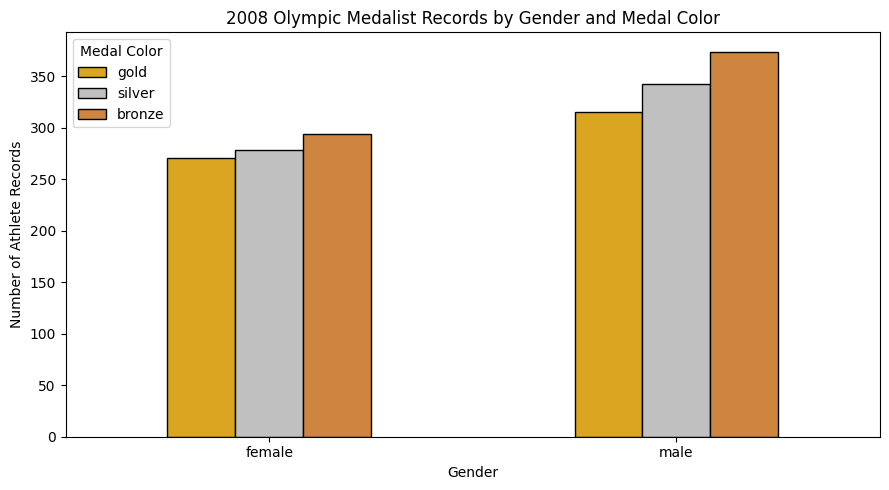

In [8]:
# Use the pivot table to make a grouped bar chart.
medal_pivot[["gold", "silver", "bronze"]].plot(kind="bar", figsize=(9, 5),
                                                   color=["goldenrod", "silver", "peru"],
                                                   edgecolor="black")
plt.title("2008 Olympic Medalist Records by Gender and Medal Color")
plt.xlabel("Gender")
plt.ylabel("Number of Athlete Records")
plt.xticks(rotation=0)
plt.legend(title="Medal Color")
plt.tight_layout()
plt.show()

**Chart 1 interpretation:** The dataset contains **1,032 male** medalist records and **843 female** records.

## 9. Visualization 2: Sports with the most listed medalists

Next, I use `groupby()` and `size()` to count athlete records for each sport. I graph the ten largest counts in a **horizontal bar chart** because some sport names are long. This chart shows which sports account for the most athlete entries in the dataset.

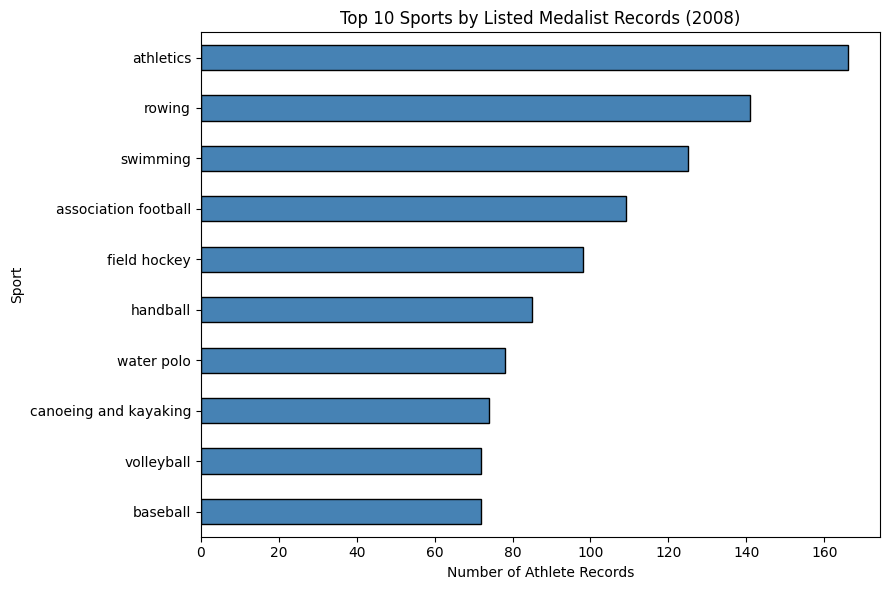

In [9]:
# Count records for each sport and show the 10 largest counts.
sport_counts = tidy_df.groupby("sport").size().sort_values(ascending=False)
top_sports = sport_counts.head(10).sort_values()

plt.figure(figsize=(9, 6))
top_sports.plot(kind="barh", color="steelblue", edgecolor="black")
plt.title("Top 10 Sports by Listed Medalist Records (2008)")
plt.xlabel("Number of Athlete Records")
plt.ylabel("Sport")
plt.tight_layout()
plt.show()

**Chart 2 interpretation:** **Athletics (166 records)**, **rowing (141)**, and **swimming (125)** have the largest counts in this dataset. 